# Aggregate Quantification Pipeline
**Project:** Protein aggregate analysis in *N. furzeri* and human retina  
**Microscope:** Zeiss LSM 900 · 40× objective · 0.5× or 0.8× zoom  
**Input:** `.czi` (z-stack) or `.tif/.tiff` (max-projected)  
**Channels:**
- *Humans*: CH0 = DAPI · CH1 = 647/magenta (protein of interest)
- *Killifish:* CH0 = Cell Marker · CH2 = Aggregates · CH3 = DAPI / area

---

### Pipeline overview
1. Load file → protein channel extracted, pixel sizes read from metadata  
2. Background subtraction (rolling ball per z-plane)  
3. Tissue mask (Otsu) → threshold computed on tissue pixels on the aggregate projection  
4. Three-filter binary mask:  
   - **Intensity** — top N% of tissue voxels  
   - **Size** — removes sub-resolution noise and cell bodies  
   - **Local contrast** — keeps objects brighter than immediate surroundings  
5. Metrics from clean mask (full image + per layer if mask provided)  
6. Binary mask saved as TIFF for thesis figures  

### How to use
1. **Cell 2** — set `file_path` in `BASE_CONFIG`. That is the only required change.  
   Optionally set `layer_mask_path` for layer-specific metrics.  
2. Run all cells top to bottom  
3. **Cell 14e** — inspect threshold preview. If wrong, adjust `threshold_percentile`  
   or `threshold_scale` in `PROTEIN_CONFIGS` and re-run 14d + 14e only.  

### Protein parameters are loaded automatically  
The protein name is parsed from the filename and matched to `PROTEIN_CONFIGS`.  
No manual config selection needed.

---

## Anaconda/Miniconda Setup
- Install [Anaconda or Miniconda](https://www.anaconda.com/download/success?reg=skipped)
- Run Conda
  - Windows: Start menu -> Anaconda / Miniconda -> Conda PowerShell
  - macOS: Terminal (Runs Conda by default)  
- Create new Conda environment `conda create -y -n lab python=3.12`
- Activate Conda environment `conda activate lab`
- Install Conda & Python packages:  
  `conda install -y -c conda-forge scikit-image scipy numpy pandas matplotlib seaborn tifffile jupyter`  
  `pip install --no-binary bioio bioio-czi`
- Update Conda packages `conda upgrade --all`
- Start Jupyter notebook from Conda `jupyter lab`


## Imports

In [1]:
from __future__ import annotations
import re, warnings, os
from pathlib import Path
from typing import TypeAlias

%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import seaborn as sns
from bioio import BioImage
from scipy.ndimage import distance_transform_edt
from skimage import filters, morphology
from skimage.color import label2rgb
from skimage.measure import label, regionprops, regionprops_table
from skimage.morphology import ball, closing, dilation, disk
from skimage.restoration import rolling_ball
from skimage.segmentation import clear_border, find_boundaries
from skimage.transform import resize
import tifffile

from metadata_parser import parse_filename

# Seaborn theme
sns.set_theme(
    style="dark",
    font_scale=1.1,
    rc={
        # ── COLORS ──────────────────────────────────────────────────────────────
        "axes.facecolor": "#1a1a2e",
        "axes.edgecolor": "white",
        "axes.labelcolor": "white",
        "axes.titlecolor": "white",
        "figure.facecolor": "#1a1a2e",
        "text.color": "white",
        "xtick.color": "white",
        "ytick.color": "white",
        "grid.color": "white",
        "grid.alpha": 0.1,
        "savefig.facecolor": "#1a1a2e",
        "savefig.edgecolor": "#1a1a2e",
        
        # ── SPINES ──────────────────────────────────────────────────────────────
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": False,
        "axes.spines.bottom": False,
        "axes.linewidth": 0,
        
        # ── FONT SIZES ──────────────────────────────────────────────────────────
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.titlesize": 13,
        "legend.fontsize": 9,
        
        # ── PADDING / MARGINS ───────────────────────────────────────────────────
        "axes.labelpad": 8,
        "axes.titlepad": 12,
        "xtick.major.pad": 6,
        "ytick.major.pad": 6,
        
        # ── LAYOUT ──────────────────────────────────────────────────────────────
        "figure.autolayout": True,
        "figure.constrained_layout.use": False,
        
        # ── LINES & MARKERS ─────────────────────────────────────────────────────
        "lines.linewidth": 1.2,
        "lines.markersize": 6,
        "patch.linewidth": 0.5,
        "hatch.linewidth": 0.5,
        
        # ── AXES ────────────────────────────────────────────────────────────────
        "axes.grid": False,
        "axes.axisbelow": True,
        
        # ── TICKS ───────────────────────────────────────────────────────────────
        "xtick.major.size": 5,
        "xtick.minor.size": 2.5,
        "ytick.major.size": 5,
        "ytick.minor.size": 2.5,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "xtick.minor.width": 0.6,
        "ytick.minor.width": 0.6,
        "xtick.direction": "out",
        "ytick.direction": "out",
        
        # ── LEGEND ──────────────────────────────────────────────────────────────
        "legend.frameon": True,
        "legend.framealpha": 0.6,
        "legend.fancybox": False,
        "legend.edgecolor": "white",
        "legend.facecolor": "#1a1a2e",
        "legend.borderpad": 0.8,
        "legend.labelspacing": 0.5,
        "legend.handlelength": 1.5,
        "legend.handletextpad": 0.5,
    }
)

# Disable tight_layout() (already set globally)
plt.rcParams["figure.autolayout"] = True

from matplotlib.patches import FancyBboxPatch
from matplotlib.transforms import Bbox
def round_axes_corners(ax, corner_radius=0.02, facecolor="none", edgecolor="white", linewidth=0.8):
    """
    Add rounded corners to axes frame.
    corner_radius: fraction of axes size (0-1)
    """
    # Get axes position in figure coordinates
    bbox = ax.get_window_extent().transformed(ax.figure.transFigure.inverted())
    
    # Create fancy box patch with rounded corners
    fancy_box = FancyBboxPatch(
        (bbox.x0, bbox.y0),
        bbox.width,
        bbox.height,
        boxstyle=f"round,pad={corner_radius}",
        transform=ax.figure.transFigure,
        facecolor=facecolor,
        edgecolor=edgecolor,
        linewidth=linewidth,
        zorder=10,
    )
    ax.figure.add_artist(fancy_box)

## Configuration

> 
- **`PROTEIN_CONFIGS`** — per-protein threshold, size, and local contrast parameters.  
  These are starting values — validate against young vs old images before interpreting results.  
- **`BASE_CONFIG`** — universal settings. Only `file_path` changes between runs.  
- **`LAYER_NAMES`** — edit to match how you label layers in Fiji.


In [2]:
# 36wo_1629_488_magenta_zpr3_647_green_app_wt_inner
# 36wo_1632_488_magenta_zpr3_647_green_app_wt_inner
# 36wo_1630_488_magenta_zpr3_647_green_app_wt_inner

BASE_PATH = "Data/Killifish/APP 36wo"
FILE_NAME = "36wo_1630_488_magenta_zpr3_647_green_app_wt_inner"
CZI_FILE_NAME = f"{BASE_PATH}/{FILE_NAME}.czi"


# ── Per-protein parameters ────────────────────────────────────────────────────
# threshold_percentile : Nth percentile of tissue voxel intensities used as cutoff.
#   Higher = stricter (only very bright objects). Lower = more sensitive.
#   Validate by inspecting the binary mask in cell 14e.
#
# min/max_diameter_um  : size filter bounds. Objects outside this range removed.
#
# local_contrast_min   : object_mean / surrounding_ring_mean threshold.
#   > 1.4 recommended for APP/αSyn. > 1.5 for tau/pTau (diffuse laminar staining).

PROTEIN_CONFIGS = {
    "app": {
        "threshold_method"    : "percentile",
        "threshold_percentile": 99.5,
        "threshold_scale"     : 1.0,
        "min_diameter_um"     : 2.0,
        "max_diameter_um"     : 25.0,
        "local_contrast_min"  : 1.4,
    },
    "tau": {
        "threshold_method"    : "percentile",
        "threshold_percentile": 99.5,
        "threshold_scale"     : 1.0,
        "min_diameter_um"     : 1.0,
        "max_diameter_um"     : 20.0,
        "local_contrast_min"  : 1.5,
    },
    "ptau": {
        "threshold_method"    : "percentile",
        "threshold_percentile": 99.5,
        "threshold_scale"     : 1.0,
        "min_diameter_um"     : 1.0,
        "max_diameter_um"     : 20.0,
        "local_contrast_min"  : 1.5,
    },
    "asyn": {
        "threshold_method"    : "percentile",
        "threshold_percentile": 95.0,
        "threshold_scale"     : 1.0,
        "min_diameter_um"     : 0.5,
        "max_diameter_um"     : 15.0,
        "local_contrast_min"  : 1.4,
    },
}

# ── Universal settings ────────────────────────────────────────────────────────
BASE_CONFIG = {
    "file_path"             : CZI_FILE_NAME,
    "protein_channel_index" : 1,        # Channel 2 = aggregates
    "area_channel_index"    : 2,        # Channel 3 = DAPI / tissue area
    "rolling_ball_radius_px": 50,       # background subtraction radius (pixels)
    "segmentation_projection": "max",    # default aggregate analysis is 2D max projection
    "use_local_contrast"    : True,
    "run_3d_comparison"     : False,     # optional side-by-side 3D metrics
    "layer_mask_path"       : None,
    "use_fluid_layer_mask"  : True,
}

# ── Layer ID map ──────────────────────────────────────────────────────────────
LAYER_NAMES = {
    1: "PR",
    2: "ONL",
    3: "OPL",
    4: "INL",
    5: "IPL",
    6: "GCL",
}

## Load file
Reads the protein channel as `(Z, Y, X)` float32.  
Pixel sizes read from CZI metadata automatically — both zoom levels handled.  
Calls `build_config()` internally — resolved config returned alongside the stack.


In [3]:
def load_file() -> tuple[np.ndarray, np.ndarray, dict, dict]:
    path = Path(BASE_CONFIG["file_path"])
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

    ext = path.suffix.lower()
    meta = parse_filename(path)
    
    # ── Build config from protein name ────────────────────────────────────────
    protein = meta["protein"].lower()
    if protein not in PROTEIN_CONFIGS:
        raise ValueError(
            f"Protein '{protein}' not found in PROTEIN_CONFIGS.\n"
            f"  Known proteins : {list(PROTEIN_CONFIGS.keys())}\n"
            f"  Fix            : add an entry to PROTEIN_CONFIGS for '{protein}'."
        )
    config = {**BASE_CONFIG, **PROTEIN_CONFIGS[protein]}
    
    print(f"✓ Protein detected       : '{protein}'")
    print(f"  Threshold              : {config['threshold_method']} "
          f"{config['threshold_percentile']}th pct × {config['threshold_scale']}")
    print(f"  Size filter            : {config['min_diameter_um']}–"
          f"{config['max_diameter_um']} µm")
    print(f"  Local contrast min     : {config['local_contrast_min']}")

    # ── Load image file ───────────────────────────────────────────────────────
    n_channels = None
    channel_names = []

    match ext:
        case ".czi":
            img = BioImage(path)
            
            n_channels = getattr(img.dims, "C", None)
            channel_names = list(getattr(img, "channel_names", []) or [])
            
            px = img.physical_pixel_sizes
            px_z = float(px.Z) if px.Z is not None else 1.0
            px_y = float(px.Y) if px.Y is not None else 0.3119629
            px_x = float(px.X) if px.X is not None else 0.3119629
            
            protein_stack = (
                img.get_image_dask_data("ZYX", C=config["protein_channel_index"])
                .compute().astype(np.float32)
            )
            
            area_stack = (
                img.get_image_dask_data("ZYX", C=config["area_channel_index"])
                .compute().astype(np.float32)
            )
            is_3d = True
            
        case ".tif" | ".tiff":
            raw = tifffile.imread(path).astype(np.float32)
            if raw.ndim == 3 and raw.shape[0] <= 4:
                raw = raw[config["protein_channel_index"]]
            
            protein_stack = raw[np.newaxis, ...]
            area_stack = protein_stack
            px_z, px_y, px_x = 1.0, 0.3119629, 0.3119629
            is_3d = False
            print("⚠️  TIFF has no pixel size metadata. Defaulting to 0.5x zoom (0.31 µm/px).")
            
        case _:
            raise ValueError(f"Unsupported format: {ext}. Use .czi or .tif/.tiff")

    # ── Update metadata with image properties ──────────────────────────────────
    meta.update({
        "file_name"     : path.name,
        "px_z_um"       : px_z,
        "px_y_um"       : px_y,
        "px_x_um"       : px_x,
        "n_z_slices"    : protein_stack.shape[0],
        "n_channels"    : n_channels,
        "channel_names" : channel_names,
        "is_3d"         : is_3d,
        "image_area_um2": protein_stack.shape[-2] * px_y * protein_stack.shape[-1] * px_x,
    })
    
    config.update({"px_z_um": px_z, "px_y_um": px_y, "px_x_um": px_x})

    print(f"\n✓ Loaded : {path.name}")
    print(f"  Shape  : {protein_stack.shape}  (Z, Y, X)")
    print(f"  Channels: {n_channels} total")
    if channel_names:
        print(f"  Channel names: {channel_names}")
    print(f"  Pixel  : Z={px_z:.4f} µm  Y={px_y:.7f} µm  X={px_x:.7f} µm")

    return protein_stack, area_stack, meta, config

## Layer mask loader
Loads a 2D TIFF layer mask if `layer_mask_path` is set in `BASE_CONFIG`.  
Returns `None` if not set — all downstream cells handle both cases gracefully.

**How to create a layer mask in Fiji:**  
1. Open the image  
2. Draw an ROI over each retinal layer  
3. Fill each ROI with its layer ID value (`Edit → Fill` after setting foreground colour)  
4. Save as 8-bit TIFF  
5. Set `layer_mask_path` in `BASE_CONFIG` to that TIFF path


In [4]:
def load_layer_mask(config: dict, image_shape_yx: tuple) -> np.ndarray | None:
    path = config.get("layer_mask_path")

    if path is None:
        print("  Layer mask: not set — layer-specific metrics will be skipped.")
        return None

    mask_path = Path(path)
    if not mask_path.exists():
        print(f"  ⚠️  Layer mask not found: {mask_path}")
        print(f"       Layer-specific metrics will be skipped.")
        return None

    mask = tifffile.imread(mask_path).astype(np.uint8)
    if mask.ndim == 3:
        mask = mask[0]

    if mask.shape != image_shape_yx:
        mask = resize(
            mask, image_shape_yx,
            order=0, anti_aliasing=False, preserve_range=True,
        ).astype(np.uint8)
        print(f"  Layer mask resized to {image_shape_yx}")

    layers_found = {v: LAYER_NAMES.get(v, f"Layer_{v}")
                    for v in np.unique(mask) if v > 0}
    print(f"✓ Layer mask loaded: {mask_path.name}")
    print(f"  Layers found: {layers_found}")
    return mask

## Background subtraction

In [5]:
def subtract_projection_background(stack: np.ndarray, radius_px: int) -> np.ndarray:
    proj = stack.max(axis=0)
    background = rolling_ball(proj, radius=radius_px)
    result = stack - background[np.newaxis, :, :]
    np.clip(result, 0, None, out=result)

    print(
        f"✓ Background subtracted from every Z slice using 2D max-projection background "
        f"(r={radius_px}px); range after: [{result.min():.1f}, {result.max():.1f}]"
    )
    return result


# Threshold
Computed from **tissue pixels on the aggregate projection** (above Otsu on full stack).  
Excludes the large black background regions outside the retina which would  
otherwise drag the percentile down and produce a meaningless cutoff.

In [6]:
def compute_threshold(
    stack_bg: np.ndarray, 
    area_stack: np.ndarray, 
    config: dict
) -> tuple[float, np.ndarray]:
    area_proj = area_stack.max(axis=0)
    otsu_thresh = filters.threshold_otsu(area_proj)
    raw_tissue_2d = area_proj > otsu_thresh

    tissue_mask_2d = closing(raw_tissue_2d, footprint=disk(10))
    tissue_mask_2d = dilation(tissue_mask_2d, footprint=disk(8))

    tissue_mask = np.broadcast_to(tissue_mask_2d[np.newaxis, :, :], stack_bg.shape)

    agg_proj = stack_bg.max(axis=0)
    tissue_mask_2d = tissue_mask.max(axis=0)
    
    flat = agg_proj[tissue_mask_2d].ravel()
    flat = flat[np.isfinite(flat)]
    flat = flat[flat > 0]
    if len(flat) == 0:
        raise ValueError("Tissue mask is empty — check background subtraction.")

    method = config["threshold_method"]
    match method:
        case "otsu":
            thresh = filters.threshold_otsu(flat)
        case "triangle":
            thresh = filters.threshold_triangle(flat)
        case "li":
            thresh = filters.threshold_li(flat)
        case "percentile":
            thresh = np.percentile(flat, config["threshold_percentile"])
        case _:
            raise ValueError(f"Unknown method '{method}'.")

    thresh *= config["threshold_scale"]
    print(f"✓ Threshold ({method}): {thresh:.2f}")
    print(f"  Tissue coverage : {tissue_mask_2d.mean()*100:.1f}% of 2D field")
    print(f"  Tissue pixels   : {int(tissue_mask_2d.sum()):,}")
    return float(thresh), tissue_mask

## Binary mask — 2D projection three-filter pipeline

**Filter 1 — Intensity:** projection pixels above the computed threshold  
**Filter 2 — Size:** removes sub-resolution noise (too small) and cell bodies (too large)  
**Filter 3 — Local contrast:** keeps only objects brighter than their immediate  
surroundings (`object_mean / ring_mean > local_contrast_min`).  
This is the key filter for removing diffuse laminar staining in tau/pTau.

The output binary mask is what all metrics and thesis figures are based on.


In [7]:
def project_stack(stack: np.ndarray, method: str = "max") -> np.ndarray:
    if stack.ndim == 2:
        return stack.astype(np.float32)
    if method == "max":
        return stack.max(axis=0).astype(np.float32)
    if method == "mean":
        return stack.mean(axis=0).astype(np.float32)
    if method == "p95":
        return np.percentile(stack, 95, axis=0).astype(np.float32)
    raise ValueError("projection method must be 'max', 'mean', or 'p95'.")


def _diameter_to_area_px(diameter_um: float, px_area_um2: float) -> int:
    area_um2 = np.pi * (float(diameter_um) / 2.0) ** 2
    return max(1, int(round(area_um2 / px_area_um2)))


def _keep_labels_by_area(labeled_2d: np.ndarray, min_area_px: int, max_area_px: int) -> np.ndarray:
    if labeled_2d.max() == 0:
        return np.zeros_like(labeled_2d, dtype=bool)

    counts = np.bincount(labeled_2d.ravel())
    keep = np.zeros(len(counts), dtype=bool)
    keep[(counts >= min_area_px) & (counts <= max_area_px)] = True
    keep[0] = False
    return keep[labeled_2d]


def compute_binary_mask(
    stack_bg: np.ndarray,
    threshold: float,
    tissue_mask: np.ndarray,
    config: dict,
) -> tuple[np.ndarray, np.ndarray]:
    """Default aggregate segmentation: 2D max-projection mask.

    Returns
    -------
    clean_mask : 2D bool array
    clean_labeled : 2D int array
    """
    px_y = config.get("px_y_um", 0.3119629)
    px_x = config.get("px_x_um", 0.3119629)
    px_area = px_y * px_x

    projection_method = config.get("segmentation_projection", "max")
    image_2d = project_stack(stack_bg, method=projection_method)
    tissue_2d = tissue_mask.max(axis=0).astype(bool) if tissue_mask.ndim == 3 else tissue_mask.astype(bool)

    # Filter 1: intensity, constrained to tissue.
    binary = (image_2d > threshold) & tissue_2d

    # Filter 2: physical 2D object area from configured equivalent diameters.
    min_area_px = _diameter_to_area_px(config["min_diameter_um"], px_area)
    max_area_px = _diameter_to_area_px(config["max_diameter_um"], px_area)

    labeled_size = label(binary, connectivity=2)
    size_mask = _keep_labels_by_area(labeled_size, min_area_px, max_area_px)
    labeled_size = label(size_mask, connectivity=2)
    n_after_size = int(labeled_size.max())

    if not config.get("use_local_contrast", True):
        print("✓ Binary mask computed from 2D projection")
        print(f"  Projection method             : {projection_method}")
        print(f"  Size filter                   : {min_area_px}–{max_area_px} px")
        print(f"  After size filter             : {n_after_size} objects")
        print(f"  Local contrast filter         : SKIPPED")
        return size_mask.astype(bool), labeled_size.astype(np.int32)

    # Filter 3: 2D local contrast around each object.
    ring_pad = 3
    min_lc = config.get("local_contrast_min", 1.4)
    keep_labels = []

    for obj in regionprops(labeled_size, intensity_image=image_2d):
        y0, x0, y1, x1 = obj.bbox
        y0e = max(0, y0 - ring_pad)
        x0e = max(0, x0 - ring_pad)
        y1e = min(image_2d.shape[0], y1 + ring_pad)
        x1e = min(image_2d.shape[1], x1 + ring_pad)

        patch_label = labeled_size[y0e:y1e, x0e:x1e]
        patch_int = image_2d[y0e:y1e, x0e:x1e]
        obj_mask = patch_label == obj.label
        ring_mask = dilation(obj_mask, footprint=disk(ring_pad)) & ~obj_mask
        ring_mask &= patch_label == 0

        ring_mean = float(patch_int[ring_mask].mean()) if ring_mask.any() else 0.0
        contrast = float(obj.intensity_mean / ring_mean) if ring_mean > 0 else np.inf

        if contrast >= min_lc:
            keep_labels.append(obj.label)

    clean_mask = np.isin(labeled_size, keep_labels)
    clean_labeled = label(clean_mask, connectivity=2).astype(np.int32)
    n_final = int(clean_labeled.max())

    print("✓ Binary mask computed from 2D projection")
    print(f"  Projection method             : {projection_method}")
    print(f"  Size filter                   : {min_area_px}–{max_area_px} px")
    print(f"  After size filter             : {n_after_size} objects")
    print(f"  After local contrast >{min_lc} : {n_final} objects kept")

    return clean_mask.astype(bool), clean_labeled


def compute_binary_mask_3d_comparison(
    stack_bg: np.ndarray,
    threshold: float,
    tissue_mask: np.ndarray,
    config: dict,
) -> tuple[np.ndarray, np.ndarray]:
    """Optional 3D segmentation for comparison only.

    Keep this separate from the default 2D workflow so 2D and 3D outputs are never mixed.
    """
    px_z = config.get("px_z_um", 1.0)
    px_y = config.get("px_y_um", 0.3119629)
    px_x = config.get("px_x_um", 0.3119629)
    voxel_vol = px_z * px_y * px_x

    min_volume = (4.0 / 3.0) * np.pi * (config["min_diameter_um"] / 2.0) ** 3
    max_volume = (4.0 / 3.0) * np.pi * (config["max_diameter_um"] / 2.0) ** 3
    min_voxels = max(1, int(round(min_volume / voxel_vol)))
    max_voxels = max(min_voxels, int(round(max_volume / voxel_vol)))

    binary = (stack_bg > threshold) & tissue_mask.astype(bool)
    labeled_3d = label(binary, connectivity=3)

    if labeled_3d.max() == 0:
        return np.zeros_like(binary, dtype=bool), labeled_3d.astype(np.int32)

    counts = np.bincount(labeled_3d.ravel())
    keep = np.zeros(len(counts), dtype=bool)
    keep[(counts >= min_voxels) & (counts <= max_voxels)] = True
    keep[0] = False

    clean = keep[labeled_3d]
    clean_labeled = label(clean, connectivity=3).astype(np.int32)

    print("✓ 3D comparison mask computed")
    print(f"  Volume filter                 : {min_voxels}–{max_voxels} voxels")
    print(f"  Objects                       : {int(clean_labeled.max())}")

    return clean.astype(bool), clean_labeled


## Measure from 2D projection mask

**Default metrics are computed from the 2D max-projection aggregate mask:**
| Metric | Definition |
|---|---|
| `puncta_count` | Number of connected objects in clean mask |
| `puncta_density_per_um2` | Count / tissue area |
| `area_fraction_pct` | % of tissue area occupied by aggregate signal |
| `integrated_density` | Sum of BG-subtracted intensity within mask voxels |
| `integrated_density_per_um2` | Integrated density normalised to tissue area |
| `mean_puncta_size_um2` | Mean area per individual punctum |

**Layer-specific metrics:** same metrics prefixed by layer name  
(e.g. `GCL_puncta_count`, `GCL_area_fraction_pct`) — only if layer mask provided.


In [8]:
MaskND: TypeAlias = np.ndarray
MetricsDict: TypeAlias = dict[str, float | int | str]


def _as_2d_mask(mask: np.ndarray) -> np.ndarray:
    return mask.max(axis=0).astype(bool) if mask.ndim == 3 else mask.astype(bool)


def _as_2d_labels(labels: np.ndarray) -> np.ndarray:
    return labels.max(axis=0).astype(np.int32) if labels.ndim == 3 else labels.astype(np.int32)


def _metrics_2d(
    binary_2d: np.ndarray,
    labeled_2d: np.ndarray,
    intensity_2d: np.ndarray,
    tissue_2d: np.ndarray,
    px_area: float,
    prefix: str = "",
) -> MetricsDict:
    tissue_2d = tissue_2d.astype(bool)
    binary_2d = binary_2d.astype(bool) & tissue_2d
    labeled_2d = label(binary_2d, connectivity=2).astype(np.int32)

    tissue_area_um2 = float(tissue_2d.sum()) * px_area
    agg_area_um2 = float(binary_2d.sum()) * px_area
    n_objects = int(labeled_2d.max())

    mean_puncta_area_um2 = 0.0
    if n_objects > 0:
        sizes_um2 = np.bincount(labeled_2d.ravel(), minlength=n_objects + 1)[1:] * px_area
        mean_puncta_area_um2 = float(np.mean(sizes_um2))

    integrated_density = float(intensity_2d[binary_2d].sum()) if binary_2d.any() else 0.0

    p = f"{prefix}_" if prefix else ""
    return {
        f"{p}puncta_count": n_objects,
        f"{p}puncta_density_per_um2": n_objects / tissue_area_um2 if tissue_area_um2 > 0 else 0.0,
        f"{p}area_fraction_pct": agg_area_um2 / tissue_area_um2 * 100 if tissue_area_um2 > 0 else 0.0,
        f"{p}integrated_density_2d": integrated_density,
        f"{p}integrated_density_per_um2": integrated_density / tissue_area_um2 if tissue_area_um2 > 0 else 0.0,
        f"{p}mean_puncta_area_um2": mean_puncta_area_um2,
        f"{p}tissue_area_um2": tissue_area_um2,
    }


def measure_from_mask(
    binary: MaskND,
    labeled: MaskND,
    stack_bg: MaskND,
    tissue_mask: MaskND,
    layer_mask: np.ndarray | None,
    meta: dict,
    config: dict,
    layer_names: dict[int, str] = LAYER_NAMES,
) -> MetricsDict:
    """Measure aggregate metrics from the default 2D projection mask."""
    px_y = meta["px_y_um"]
    px_x = meta["px_x_um"]
    px_area = px_y * px_x

    projection_method = config.get("segmentation_projection", "max")
    intensity_2d = project_stack(stack_bg, method=projection_method)
    tissue_2d = _as_2d_mask(tissue_mask)
    binary_2d = _as_2d_mask(binary)
    labeled_2d = _as_2d_labels(labeled)

    results = _metrics_2d(binary_2d, labeled_2d, intensity_2d, tissue_2d, px_area)
    results["measurement_mode"] = f"2d_{projection_method}_projection"

    if layer_mask is not None:
        for layer_id, layer_name in layer_names.items():
            layer_region = layer_mask == layer_id
            if not layer_region.any():
                continue
            layer_tissue = tissue_2d & layer_region
            layer_binary = binary_2d & layer_region
            layer_labeled = label(layer_binary, connectivity=2).astype(np.int32)
            results.update(
                _metrics_2d(
                    layer_binary,
                    layer_labeled,
                    intensity_2d,
                    layer_tissue,
                    px_area,
                    prefix=layer_name,
                )
            )
    else:
        results["layer_analysis"] = "not_run"

    for k in ["file_name", "subject", "condition", "protein", "zoom", "replicate", "species_guess", "quality_flag"]:
        results[k] = meta.get(k, "unknown")

    print("✓ 2D projection metrics computed")
    print(f"  Mode                       : {results['measurement_mode']}")
    print(f"  Puncta count               : {results['puncta_count']}")
    print(f"  Area fraction              : {results['area_fraction_pct']:.4f}%")
    print(f"  Integrated density         : {results['integrated_density_2d']:.1f}")
    print(f"  Integrated density/µm²     : {results['integrated_density_per_um2']:.4f}")
    print(f"  Mean puncta area           : {results['mean_puncta_area_um2']:.3f} µm²")
    if layer_mask is not None:
        computed = [name for _, name in layer_names.items() if f"{name}_puncta_count" in results]
        print(f"  Layers computed            : {computed}")

    return results


def measure_3d_comparison(
    binary_3d: np.ndarray,
    labeled_3d: np.ndarray,
    stack_bg: np.ndarray,
    tissue_mask: np.ndarray,
    meta: dict,
) -> MetricsDict:
    """Optional comparison metrics for a true 3D mask."""
    px_z = meta["px_z_um"]
    px_y = meta["px_y_um"]
    px_x = meta["px_x_um"]
    voxel_volume = px_z * px_y * px_x

    n_objects = int(labeled_3d.max())
    volume_um3 = float(binary_3d.sum()) * voxel_volume
    tissue_volume_um3 = float(tissue_mask.sum()) * voxel_volume
    integrated_density_3d = float(stack_bg[binary_3d].sum()) if binary_3d.any() else 0.0

    mean_puncta_volume_um3 = 0.0
    if n_objects > 0:
        sizes_um3 = np.bincount(labeled_3d.ravel(), minlength=n_objects + 1)[1:] * voxel_volume
        mean_puncta_volume_um3 = float(np.mean(sizes_um3))

    return {
        "measurement_mode": "3d_comparison",
        "puncta_count": n_objects,
        "aggregate_volume_um3": volume_um3,
        "tissue_volume_um3": tissue_volume_um3,
        "volume_fraction_pct": volume_um3 / tissue_volume_um3 * 100 if tissue_volume_um3 > 0 else 0.0,
        "integrated_density_3d": integrated_density_3d,
        "integrated_density_per_um3": integrated_density_3d / tissue_volume_um3 if tissue_volume_um3 > 0 else 0.0,
        "mean_puncta_volume_um3": mean_puncta_volume_um3,
    }


---
## 1:  Initialize
The most common iteration is adjusting `threshold_percentile` in `PROTEIN_CONFIGS` then re-running cells below.

In [9]:
# Protein detected and config resolved automatically from filename.
protein_stack, area_stack, meta, config = load_file()

# Returns `None` if `layer_mask_path` is not set. Auto-layer cells below can create masks too.
layer_mask_external = load_layer_mask(config, protein_stack.shape[-2:])
print(os.linesep)

# Background subtraction
stack_bg = subtract_projection_background(protein_stack, config["rolling_ball_radius_px"])


✓ Protein detected       : 'app'
  Threshold              : percentile 99.5th pct × 1.0
  Size filter            : 2.0–25.0 µm
  Local contrast min     : 1.4

✓ Loaded : 36wo_1630_488_magenta_zpr3_647_green_app_wt_inner.czi
  Shape  : (14, 1024, 1024)  (Z, Y, X)
  Channels: 3 total
  Channel names: [np.str_('AF488-T1'), np.str_('AF647-T1'), np.str_('DAPI-T2')]
  Pixel  : Z=1.0000 µm  Y=0.1949768 µm  X=0.1949768 µm
  Layer mask: not set — layer-specific metrics will be skipped.


✓ Background subtracted from every Z slice using 2D max-projection background (r=50px); range after: [0.0, 245.9]


---
### 2: Threshold Preview with Binary Mask
If mask looks wrong: adjust `threshold_percentile` or `threshold_scale` in `PROTEIN_CONFIGS`.

Three panels: raw max projection · BG-subtracted · binary mask.

Binary mask = which voxels are in the top X% brightest tissue signal  
after background removal. No shape assumptions yet — pure intensity cutoff.

What to look for:
- Sparse bright puncta in the mask → good, proceed  
- Whole tissue lit up → raise `threshold_percentile` in `PROTEIN_CONFIGS`
- Almost nothing → lower `threshold_percentile`  

✓ Threshold (percentile): 143.72
  Tissue coverage : 86.9% of 2D field
  Tissue pixels   : 911,163




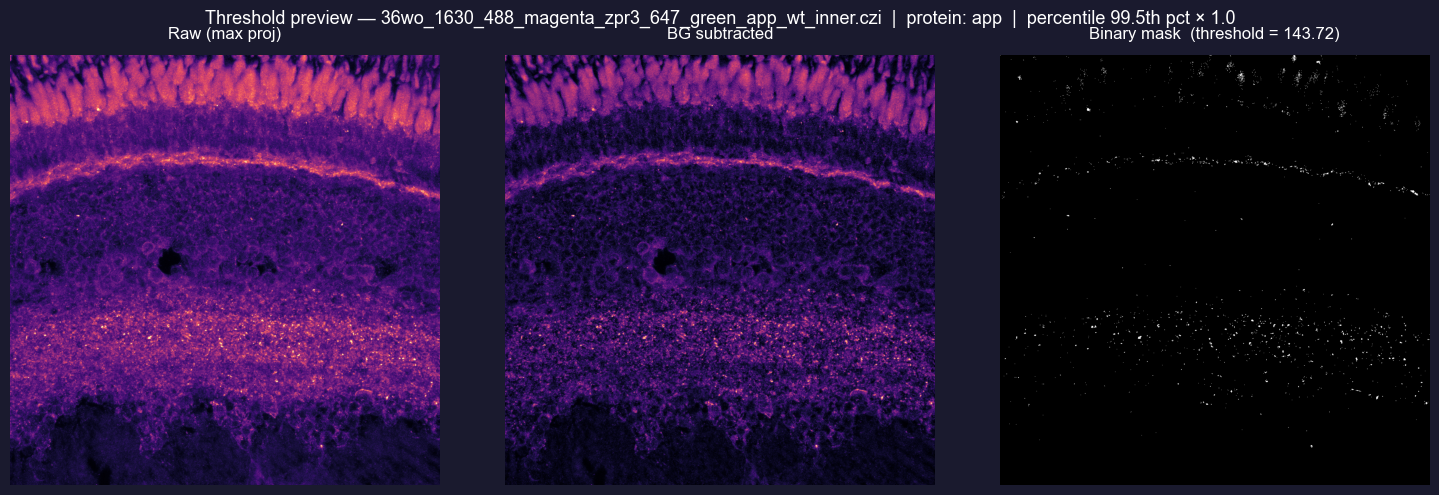

  Threshold value      : 143.72
  Tissue mask coverage : 0.50%
  ✓  Coverage looks reasonable — proceed to segmentation.


In [10]:
# Thresholding + Tissue Mask; `tissue_mask` is reused in cell 14g for metric normalisation.
threshold, tissue_mask = compute_threshold(stack_bg, area_stack, config)
print (os.linesep)

# Preview Threshold
max_raw = protein_stack.max(axis=0)
max_bg  = stack_bg.max(axis=0)
binary  = (max_bg > threshold).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(
    f"Threshold preview — {meta['file_name']}  |  protein: {meta['protein']}  |  "
    f"{config['threshold_method']} {config['threshold_percentile']}th pct "
    f"× {config['threshold_scale']}"
)

axes[0].imshow(max_raw, cmap="magma")
axes[0].set_title("Raw (max proj)")
axes[0].axis("off")

axes[1].imshow(max_bg, cmap="magma")
axes[1].set_title("BG subtracted")
axes[1].axis("off")

axes[2].imshow(binary, cmap="gray")
axes[2].set_title(f"Binary mask  (threshold = {threshold:.2f})")
axes[2].axis("off")

plt.show()

tissue_2d = tissue_mask.max(axis=0).astype(bool)
coverage = 100 * (binary.astype(bool) & tissue_2d).sum() / max(1, tissue_2d.sum())
print(f"  Threshold value      : {threshold:.2f}")
print(f"  Tissue mask coverage : {coverage:.2f}%")

match True:
    case _ if coverage > 30:
        print("  ⚠️  High — raise threshold_percentile in PROTEIN_CONFIGS.")
    case _ if coverage < 0.1:
        print("  ⚠️  Very low — lower threshold_percentile in PROTEIN_CONFIGS.")
    case _:
        print("  ✓  Coverage looks reasonable — proceed to segmentation.")

## 3: Tissue Area Visualization

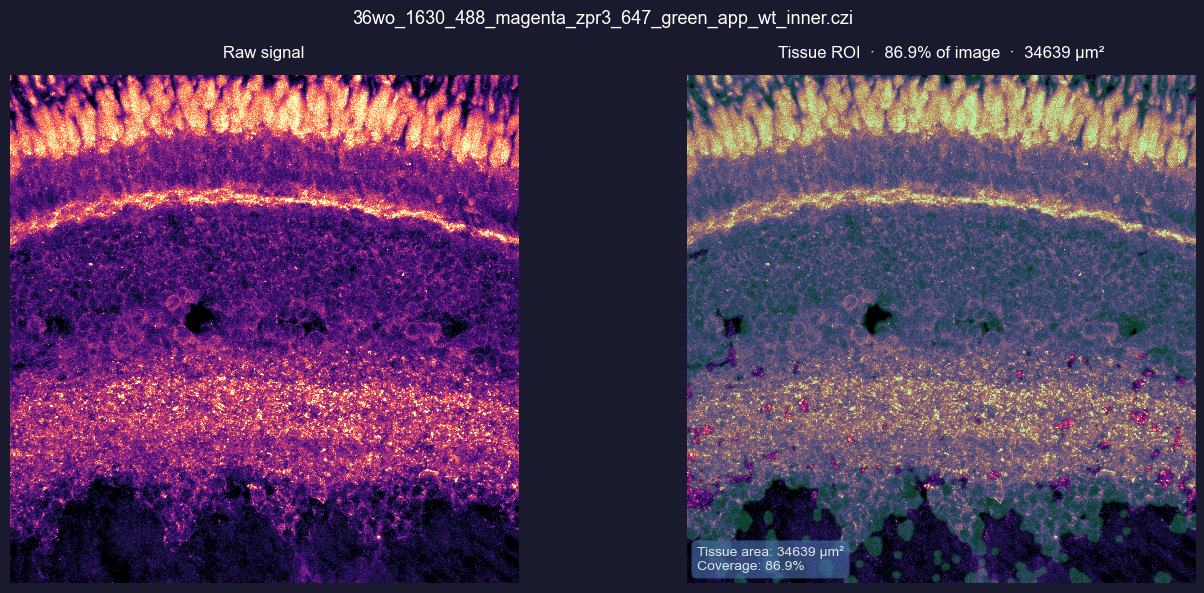

In [11]:
max_raw   = protein_stack.max(axis=0)
tissue_2d = tissue_mask.max(axis=0)

# Normalise raw for display
display = max_raw.astype(np.float32)
p1, p99 = np.percentile(display, (1, 99))
display  = np.clip((display - p1) / (p99 - p1 + 1e-6), 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(meta['file_name'])

# ── Left: raw ────────────────────────────────────────────────────────────────
axes[0].imshow(display, cmap="magma", interpolation="nearest")
axes[0].set_title("Raw signal")
axes[0].axis("off")

# ── Right: tissue overlay ─────────────────────────────────────────────────────
axes[1].imshow(display, cmap="magma", interpolation="nearest")

tissue_overlay = np.zeros((*display.shape, 4), dtype=np.float32)
tissue_overlay[tissue_2d, :]  = [0.18, 0.80, 0.44, 0.30]  # emerald green fill

# Draw tissue boundary as a bright line
boundary = find_boundaries(tissue_2d, mode="outer")
boundary_overlay = np.zeros((*display.shape, 4), dtype=np.float32)
boundary_overlay[boundary, :] = [0.18, 0.80, 0.44, 0.95]  # crisp green edge

axes[1].imshow(tissue_overlay)
axes[1].imshow(boundary_overlay)

coverage = tissue_2d.mean() * 100
tissue_area = tissue_2d.sum() * meta["px_y_um"] * meta["px_x_um"]
axes[1].set_title(
    f"Tissue ROI  ·  {coverage:.1f}% of image  ·  {tissue_area:.0f} µm²",
)
axes[1].axis("off")

# Annotation in corner
axes[1].text(
    0.02, 0.02,
    f"Tissue area: {tissue_area:.0f} µm²\nCoverage: {coverage:.1f}%",
    transform=axes[1].transAxes,
    alpha=0.85,
    verticalalignment="bottom",
    bbox=dict(boxstyle="round,pad=0.4", alpha=0.6, edgecolor="none"),
)

plt.show()

### 4: Compute binary mask (all three filters)

In [12]:
clean_mask, labeled = compute_binary_mask(stack_bg, threshold, tissue_mask, config)

✓ Binary mask computed from 2D projection
  Projection method             : max
  Size filter                   : 83–12912 px
  After size filter             : 0 objects
  After local contrast >1.4 : 0 objects kept


----
# 8: Automatic retinal layer mask from global nuclear bands

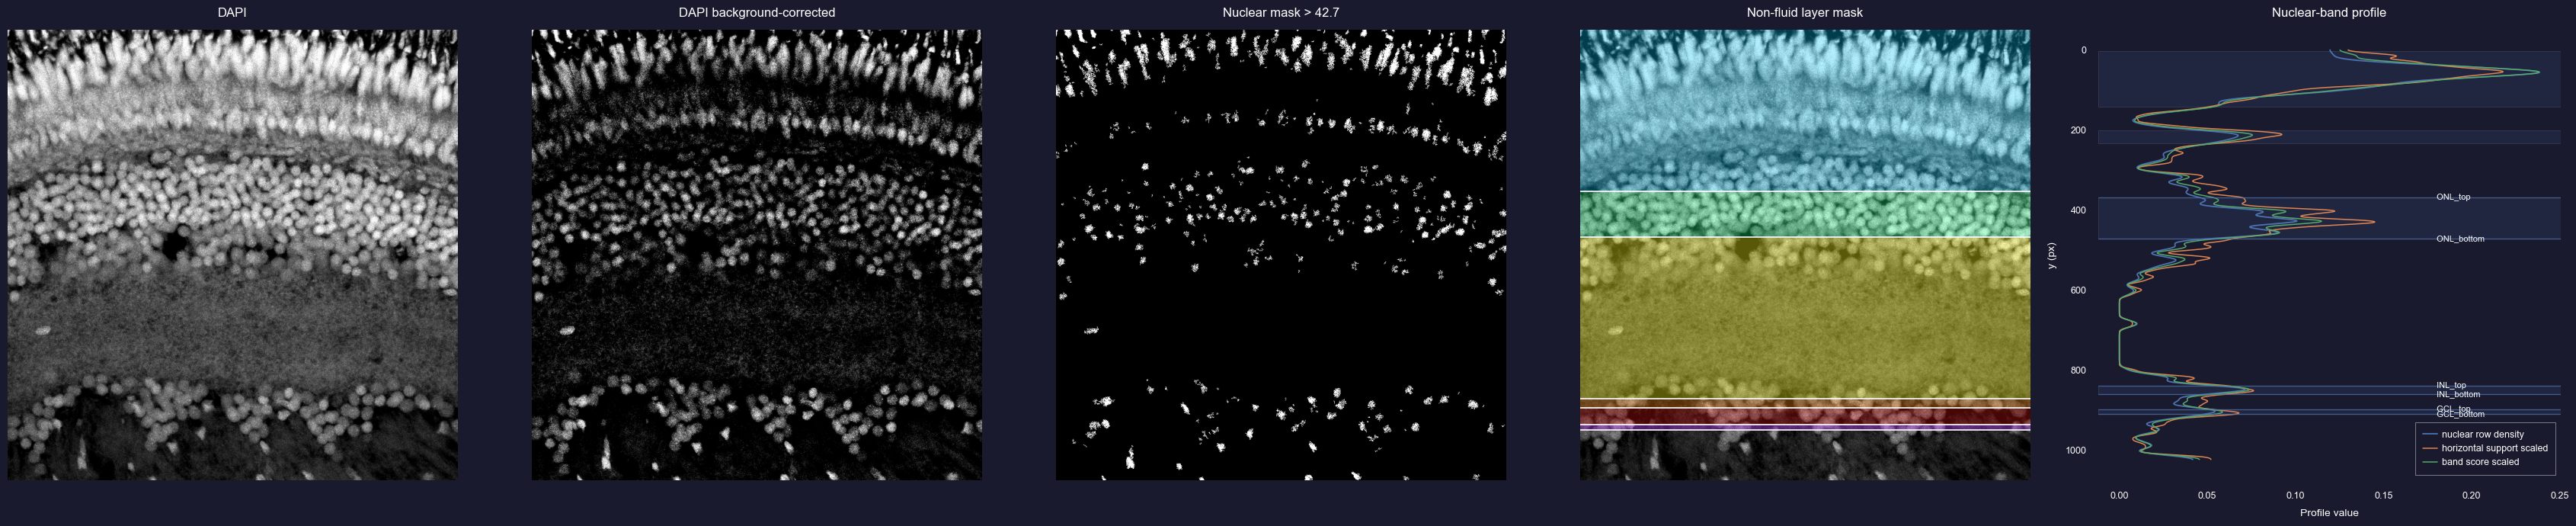

Non-fluid layer mask created.
  1: PR  pixels=376,832
  2: ONL pixels=107,520
  3: OPL pixels=373,760
  4: INL pixels=23,552
  5: IPL pixels=37,888
  6: GCL pixels=13,312


In [13]:
from scipy.ndimage import binary_closing, binary_opening, gaussian_filter, gaussian_filter1d
from skimage.filters import threshold_multiotsu
from skimage.measure import label as sk_label

LAYER_PALETTE = {
    1: [0.00, 0.80, 1.00, 0.30],
    2: [0.10, 1.00, 0.50, 0.30],
    3: [1.00, 1.00, 0.10, 0.35],
    4: [1.00, 0.55, 0.10, 0.35],
    5: [1.00, 0.10, 0.10, 0.28],
    6: [0.75, 0.25, 1.00, 0.40],
}


def norm01(x: np.ndarray) -> np.ndarray:
    x = np.asarray(x, dtype=np.float32)
    lo, hi = np.nanmin(x), np.nanmax(x)
    return np.clip((x - lo) / (hi - lo + 1e-6), 0, 1)


def get_tissue_2d(tissue_mask: np.ndarray) -> np.ndarray:
    return tissue_mask.max(axis=0).astype(bool) if tissue_mask.ndim == 3 else tissue_mask.astype(bool)


def remove_small_components_2d(mask: np.ndarray, min_px: int = 8) -> np.ndarray:
    labels = sk_label(mask, connectivity=2)
    if labels.max() == 0:
        return np.zeros_like(mask, dtype=bool)
    counts = np.bincount(labels.ravel())
    keep = counts >= int(min_px)
    keep[0] = False
    return keep[labels]


def make_nuclear_mask(
    area_stack: np.ndarray,
    tissue_mask: np.ndarray,
    projection: str = "p95",
    bg_sigma_frac: float = 0.045,
    min_object_px: int = 8,
) -> tuple[np.ndarray, dict]:
    dapi_2d = project_stack(area_stack, method=projection)
    tissue_2d = get_tissue_2d(tissue_mask)
    H, W = dapi_2d.shape

    sigma = max(3, int(round(H * bg_sigma_frac)))
    dapi_bg = gaussian_filter(dapi_2d, sigma=sigma)
    dapi_corr = dapi_2d - dapi_bg
    dapi_corr[dapi_corr < 0] = 0

    vals = dapi_corr[tissue_2d]
    vals = vals[np.isfinite(vals)]
    vals = vals[vals > 0]
    if vals.size < 100:
        raise RuntimeError("Not enough positive DAPI pixels inside tissue mask.")

    try:
        threshold = float(threshold_multiotsu(vals, classes=3)[-1])
    except Exception:
        threshold = float(np.percentile(vals, 90))

    nuclei_mask = (dapi_corr > threshold) & tissue_2d
    nuclei_mask = remove_small_components_2d(nuclei_mask, min_px=min_object_px)

    return nuclei_mask, {
        "dapi_2d": dapi_2d,
        "dapi_corr": dapi_corr,
        "dapi_bg": dapi_bg,
        "tissue_2d": tissue_2d,
        "nuc_threshold": threshold,
    }


def true_runs(active: np.ndarray) -> list[tuple[int, int]]:
    active = np.asarray(active, dtype=bool)
    if not active.any():
        return []
    idx = np.flatnonzero(active)
    breaks = np.where(np.diff(idx) > 1)[0]
    starts = np.r_[idx[0], idx[breaks + 1]]
    ends = np.r_[idx[breaks], idx[-1]]
    return [(int(a), int(b)) for a, b in zip(starts, ends)]


def merge_close_runs(runs: list[tuple[int, int]], max_gap_px: int) -> list[tuple[int, int]]:
    if not runs:
        return []
    merged = [runs[0]]
    for y0, y1 in runs[1:]:
        py0, py1 = merged[-1]
        if y0 - py1 <= max_gap_px:
            merged[-1] = (py0, y1)
        else:
            merged.append((y0, y1))
    return merged


def horizontal_support(nuclei_mask: np.ndarray, n_bins: int = 32) -> np.ndarray:
    H, W = nuclei_mask.shape
    edges = np.linspace(0, W, n_bins + 1).astype(int)
    support = np.zeros(H, dtype=np.float32)

    for x0, x1 in zip(edges[:-1], edges[1:]):
        if x1 <= x0:
            continue
        local = gaussian_filter1d(nuclei_mask[:, x0:x1].mean(axis=1).astype(np.float32), sigma=max(2, H // 220))
        if local.max() <= 0:
            continue
        support += (local > max(0.001, 0.12 * local.max())).astype(np.float32)

    support /= float(max(1, n_bins))
    return gaussian_filter1d(support, sigma=max(2, H // 220))


def find_nuclear_bands(nuclei_mask: np.ndarray, min_support: float = 0.08) -> tuple[list[dict], dict]:
    H, W = nuclei_mask.shape
    row_density = nuclei_mask.mean(axis=1).astype(np.float32)
    row_density_s = gaussian_filter1d(row_density, sigma=max(3, H // 140))
    row_support_s = horizontal_support(nuclei_mask, n_bins=min(40, max(12, W // 32)))
    band_score = 0.75 * norm01(row_density_s) + 0.25 * norm01(row_support_s)

    min_band_px = max(6, int(0.010 * H))
    max_merge_gap = max(4, int(0.012 * H))
    best = []

    for thr in [0.22, 0.18, 0.14, 0.10, 0.075, 0.055]:
        active = (band_score > thr) & (row_support_s >= min_support)
        active = binary_closing(active, structure=np.ones(max(3, H // 160), dtype=bool))
        active = binary_opening(active, structure=np.ones(max(2, H // 450), dtype=bool))
        runs = merge_close_runs(true_runs(active), max_gap_px=max_merge_gap)

        candidates = []
        for y0, y1 in runs:
            height = y1 - y0 + 1
            if height < min_band_px:
                continue
            candidates.append({
                "y0": int(y0),
                "y1": int(y1),
                "height": int(height),
                "center": float(0.5 * (y0 + y1)),
                "peak_density": float(row_density_s[y0:y1 + 1].max()),
                "mean_support": float(row_support_s[y0:y1 + 1].mean()),
                "score_sum": float(band_score[y0:y1 + 1].sum()),
            })

        if len(candidates) > len(best):
            best = candidates
        if len(candidates) >= 3:
            break

    if len(best) < 3:
        raise RuntimeError(f"Need at least 3 nuclear bands; found {len(best)}.")

    return sorted(best, key=lambda b: b["center"]), {
        "row_density_s": row_density_s,
        "row_support_s": row_support_s,
        "band_score": band_score,
    }


def build_nonfluid_layer_mask(H: int, W: int, onl: dict, inl: dict, gcl: dict) -> tuple[np.ndarray, dict]:
    boundaries = {
        "ONL_top": int(onl["y0"]),
        "ONL_bottom": int(onl["y1"]),
        "INL_top": int(inl["y0"]),
        "INL_bottom": int(inl["y1"]),
        "GCL_top": int(gcl["y0"]),
        "GCL_bottom": int(gcl["y1"]),
    }

    mask = np.zeros((H, W), dtype=np.uint8)
    mask[:boundaries["ONL_top"], :] = 1
    mask[boundaries["ONL_top"]:boundaries["ONL_bottom"] + 1, :] = 2
    mask[boundaries["ONL_bottom"] + 1:boundaries["INL_top"], :] = 3
    mask[boundaries["INL_top"]:boundaries["INL_bottom"] + 1, :] = 4
    mask[boundaries["INL_bottom"] + 1:boundaries["GCL_top"], :] = 5
    mask[boundaries["GCL_top"]:boundaries["GCL_bottom"] + 1, :] = 6
    return mask, boundaries


def make_nonfluid_layer_mask(area_stack: np.ndarray, tissue_mask: np.ndarray) -> tuple[np.ndarray, dict]:
    nuclei_mask, diag = make_nuclear_mask(area_stack, tissue_mask)
    candidates, profile_diag = find_nuclear_bands(nuclei_mask)
    onl, inl, gcl = candidates[-3:]
    H, W = nuclei_mask.shape
    layer_mask_nonfluid, boundaries = build_nonfluid_layer_mask(H, W, onl, inl, gcl)

    diag.update({
        "nuclei_mask": nuclei_mask,
        "candidates": candidates,
        "onl": onl,
        "inl": inl,
        "gcl": gcl,
        "boundaries": boundaries,
        **profile_diag,
    })
    return layer_mask_nonfluid, diag


def make_layer_overlay(layer_mask: np.ndarray, palette: dict = LAYER_PALETTE) -> np.ndarray:
    overlay = np.zeros((*layer_mask.shape, 4), dtype=np.float32)
    for layer_id, rgba in palette.items():
        overlay[layer_mask == layer_id] = rgba
    return overlay


def preview_nonfluid_layers(layer_mask_nonfluid: np.ndarray, diag: dict) -> None:
    dapi_2d = diag["dapi_2d"]
    tissue_2d = diag["tissue_2d"]
    nuclei_mask = diag["nuclei_mask"]
    boundaries = diag["boundaries"]
    H, W = dapi_2d.shape

    p1, p99 = np.percentile(dapi_2d[tissue_2d], (1, 99))
    disp = np.clip((dapi_2d - p1) / (p99 - p1 + 1e-6), 0, 1)

    positive_corr = diag["dapi_corr"][diag["dapi_corr"] > 0]
    if positive_corr.size > 100:
        c1, c99 = np.percentile(positive_corr, (1, 99))
    else:
        c1, c99 = 0, max(1, diag["dapi_corr"].max())
    corr_disp = np.clip((diag["dapi_corr"] - c1) / (c99 - c1 + 1e-6), 0, 1)

    fig, axes = plt.subplots(1, 5, figsize=(34, 7))
    axes[0].imshow(disp, cmap="gray"); axes[0].set_title("DAPI"); axes[0].axis("off")
    axes[1].imshow(corr_disp, cmap="gray"); axes[1].set_title("DAPI background-corrected"); axes[1].axis("off")
    axes[2].imshow(nuclei_mask, cmap="gray"); axes[2].set_title(f"Nuclear mask > {diag['nuc_threshold']:.1f}"); axes[2].axis("off")
    axes[3].imshow(disp, cmap="gray"); axes[3].imshow(make_layer_overlay(layer_mask_nonfluid)); axes[3].set_title("Non-fluid layer mask"); axes[3].axis("off")

    line_items = [
        ("ONL_top", boundaries["ONL_top"]),
        ("ONL_bottom", boundaries["ONL_bottom"]),
        ("INL_top", boundaries["INL_top"]),
        ("INL_bottom", boundaries["INL_bottom"]),
        ("GCL_top", boundaries["GCL_top"]),
        ("GCL_bottom", boundaries["GCL_bottom"]),
    ]
    for name, y in line_items:
        axes[3].axhline(y, color="white", lw=1.2)

    axes[4].plot(diag["row_density_s"], range(H), lw=1.3, label="nuclear row density")
    axes[4].plot(diag["row_support_s"] * np.nanmax(diag["row_density_s"]), range(H), lw=1.1, label="horizontal support scaled")
    axes[4].plot(diag["band_score"] * np.nanmax(diag["row_density_s"]), range(H), lw=1.1, label="band score scaled")
    for c in diag["candidates"]:
        axes[4].axhspan(c["y0"], c["y1"], alpha=0.14)
    for name, y in line_items:
        axes[4].axhline(y, lw=1, alpha=0.65)
        axes[4].text(np.nanmax(diag["row_density_s"]) * 0.75, y, f" {name}", va="center", fontsize=8)
    axes[4].invert_yaxis(); axes[4].set_xlabel("Profile value"); axes[4].set_ylabel("y (px)"); axes[4].set_title("Nuclear-band profile"); axes[4].legend(loc="lower right")
    plt.tight_layout(); plt.show()

    print("Non-fluid layer mask created.")
    for layer_id, layer_name in LAYER_NAMES.items():
        print(f"  {layer_id}: {layer_name:<3} pixels={(layer_mask_nonfluid == layer_id).sum():,}")


layer_mask_nonfluid, layer_diag_nonfluid = make_nonfluid_layer_mask(area_stack, tissue_mask)
preview_nonfluid_layers(layer_mask_nonfluid, layer_diag_nonfluid)


---

# 8.a:  Simple fluid layer mask from existing non-fluid layer_mask

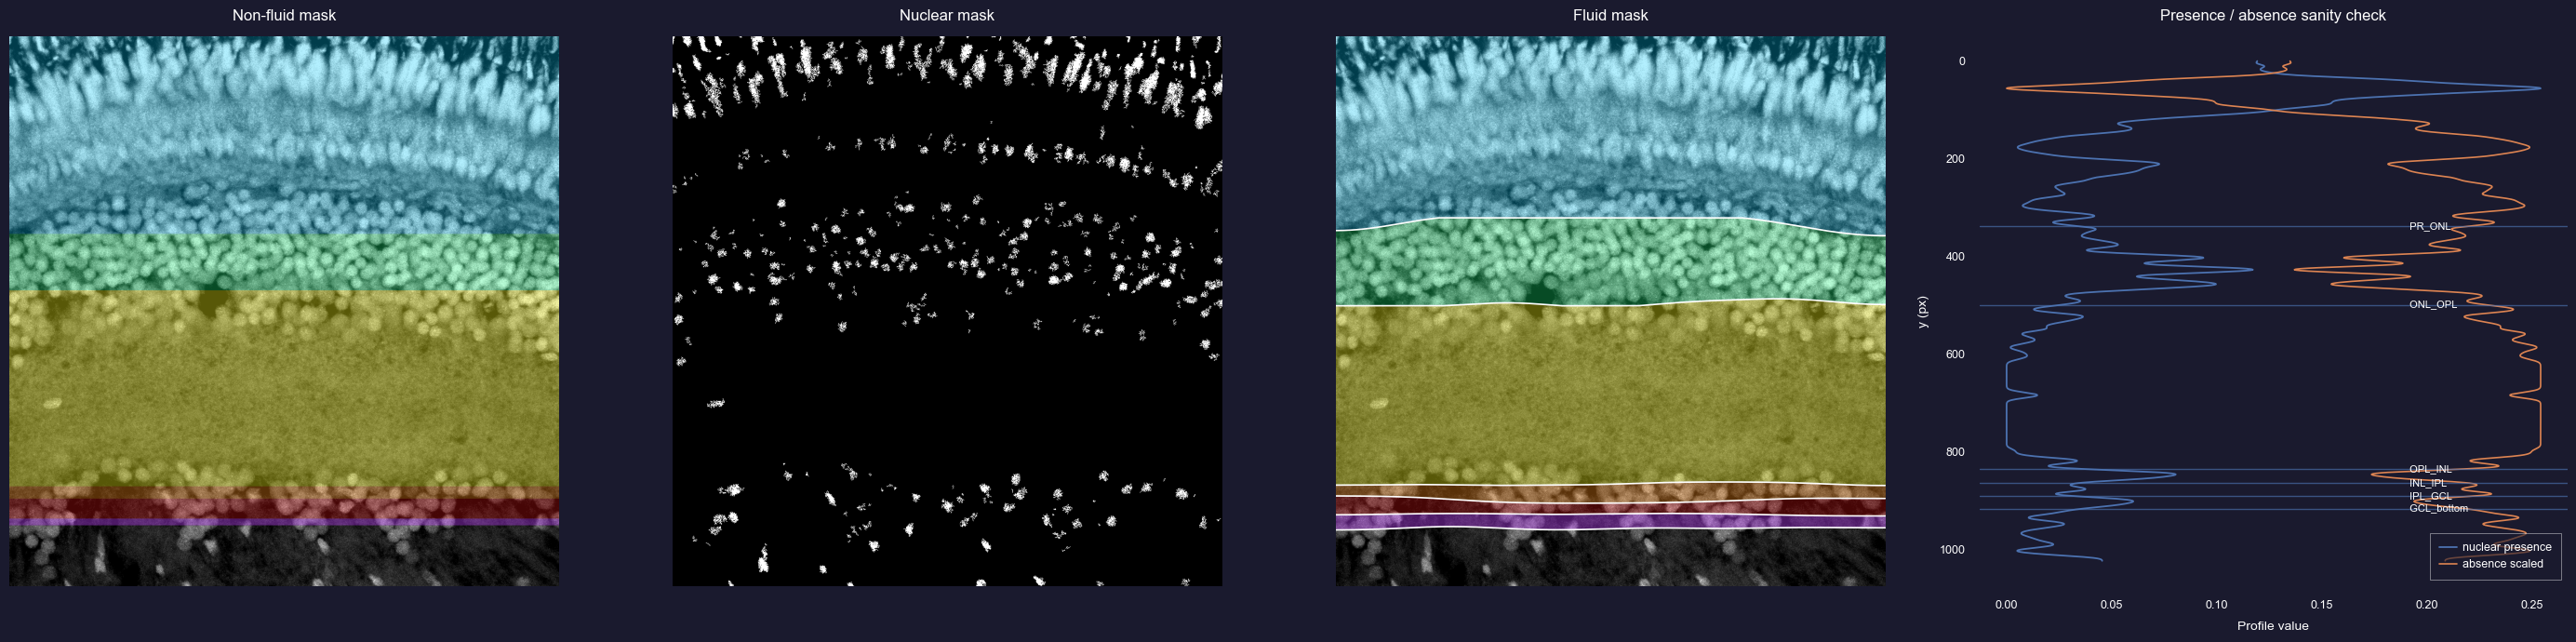

Final layer mask selected: fluid
Fluid controls: strength=0.65, max_shift=46 px, smooth=82 px

Final layer pixel summary:
  1: PR  pixels=353,863
  2: ONL pixels=155,684
  3: OPL pixels=344,350
  4: INL pixels=30,901
  5: IPL pixels=26,820
  6: GCL pixels=27,633


In [14]:
def layer_row_bounds(mask: np.ndarray, layer_id: int) -> tuple[int, int] | None:
    rows = np.where((mask == layer_id).any(axis=1))[0]
    if rows.size == 0:
        return None
    return int(rows.min()), int(rows.max())


def local_envelope_from_nuclei(
    nuclei_mask: np.ndarray,
    base_y0: int,
    base_y1: int,
    *,
    x_step: int,
    half_win: int,
    search_margin: int,
    q_low: float,
    q_high: float,
    pad: int,
    min_pixels: int,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    H, W = nuclei_mask.shape
    x_centers = np.arange(0, W, x_step, dtype=int)
    if x_centers[-1] != W - 1:
        x_centers = np.r_[x_centers, W - 1]

    sy0 = max(0, int(base_y0) - int(search_margin))
    sy1 = min(H - 1, int(base_y1) + int(search_margin))
    top_vals, bottom_vals = [], []

    for xc in x_centers:
        x0 = max(0, int(xc - half_win))
        x1 = min(W, int(xc + half_win + 1))
        yy, _ = np.nonzero(nuclei_mask[sy0:sy1 + 1, x0:x1])
        if yy.size < min_pixels:
            top_vals.append(np.nan)
            bottom_vals.append(np.nan)
            continue
        y_abs = yy + sy0
        top_vals.append(float(np.percentile(y_abs, q_low)) - pad)
        bottom_vals.append(float(np.percentile(y_abs, q_high)) + pad)

    return x_centers, np.asarray(top_vals, dtype=np.float32), np.asarray(bottom_vals, dtype=np.float32)


def interp_smooth(values: np.ndarray, x_centers: np.ndarray, width: int, fallback: float, smooth_px: int) -> np.ndarray:
    values = np.asarray(values, dtype=np.float32)
    valid = np.isfinite(values)
    if valid.sum() < 2:
        out = np.full(width, float(fallback), dtype=np.float32)
    else:
        x = np.arange(width, dtype=np.float32)
        out = np.interp(x, x_centers[valid], values[valid], left=values[valid][0], right=values[valid][-1])
    return gaussian_filter1d(out, sigma=max(1, int(smooth_px))).astype(np.float32)


def clamp_to_base(values: np.ndarray, base_y: float, max_shift_px: int, fluid_strength: float) -> np.ndarray:
    values = np.clip(values, base_y - max_shift_px, base_y + max_shift_px)
    return (base_y + fluid_strength * (values - base_y)).astype(np.float32)


def make_fluid_layer_mask(
    base_layer_mask: np.ndarray,
    nuclei_mask: np.ndarray,
    *,
    fluid_strength: float = 0.65,
    max_shift_px: int | None = None,
    smooth_px: int | None = None,
) -> tuple[np.ndarray, dict]:
    H, W = base_layer_mask.shape
    max_shift_px = max_shift_px if max_shift_px is not None else max(8, int(round(H * 0.045)))
    smooth_px = smooth_px if smooth_px is not None else max(5, int(round(W * 0.080)))

    bounds = {}
    missing = []
    for layer_id, name in LAYER_NAMES.items():
        b = layer_row_bounds(base_layer_mask, layer_id)
        if b is None:
            missing.append(f"{layer_id}:{name}")
        else:
            bounds[name] = b

    if missing:
        print(f"⚠️  Missing layers in base mask: {', '.join(missing)}")
        print("    Skipping fluid layer generation.")
        return base_layer_mask, {"error": "incomplete_base_mask", "missing": missing}

    band_params = {
        "ONL": dict(q_low=3, q_high=97, pad=2, min_pixels=8, search_mult=0.60),
        "INL": dict(q_low=3, q_high=97, pad=2, min_pixels=8, search_mult=0.60),
        "GCL": dict(q_low=2, q_high=98, pad=3, min_pixels=4, search_mult=1.00),
    }

    envelopes = {}
    for name, params in band_params.items():
        y0, y1 = bounds[name]
        band_h = y1 - y0 + 1
        x_centers, top_samples, bottom_samples = local_envelope_from_nuclei(
            nuclei_mask,
            y0,
            y1,
            x_step=max(10, W // 60),
            half_win=max(30, W // 14),
            search_margin=max(10, int(params["search_mult"] * band_h)),
            q_low=params["q_low"],
            q_high=params["q_high"],
            pad=params["pad"],
            min_pixels=params["min_pixels"],
        )
        top = interp_smooth(top_samples, x_centers, W, fallback=y0, smooth_px=smooth_px)
        bottom = interp_smooth(bottom_samples, x_centers, W, fallback=y1, smooth_px=smooth_px)
        envelopes[name] = {
            "top": clamp_to_base(top, y0, max_shift_px, fluid_strength),
            "bottom": clamp_to_base(bottom, y1, max_shift_px, fluid_strength),
            "base": (y0, y1),
            "x_centers": x_centers,
            "top_samples": top_samples,
            "bottom_samples": bottom_samples,
        }

    min_opl = max(3, int(0.004 * H))
    min_ipl = max(10, int(0.020 * H))
    min_band = max(3, int(0.006 * H))

    boundaries = np.vstack([
        envelopes["ONL"]["top"],
        envelopes["ONL"]["bottom"],
        envelopes["INL"]["top"],
        envelopes["INL"]["bottom"],
        envelopes["GCL"]["top"],
        envelopes["GCL"]["bottom"],
    ]).astype(np.float32)

    onl_y0, onl_y1 = bounds["ONL"]
    inl_y0, inl_y1 = bounds["INL"]
    gcl_y0, gcl_y1 = bounds["GCL"]

    for x in range(W):
        boundaries[1, x] = max(boundaries[1, x], boundaries[0, x] + min_band)
        boundaries[2, x] = max(boundaries[2, x], boundaries[1, x] + min_opl)
        boundaries[3, x] = max(boundaries[3, x], boundaries[2, x] + min_band)
        boundaries[4, x] = max(boundaries[4, x], boundaries[3, x] + min_ipl)
        boundaries[5, x] = max(boundaries[5, x], boundaries[4, x] + min_band)
        
        # Clamp gracefully instead of reverting to base—prevents seams
        if boundaries[5, x] >= H:
            excess = boundaries[5, x] - (H - 1)
            for i in range(6):
                boundaries[i, x] = max(0, min(boundaries[i, x] - excess, H - 1))

    boundaries = np.clip(boundaries, 0, H - 1)
    b = np.rint(boundaries).astype(int)
    fluid_mask = np.zeros((H, W), dtype=np.uint8)

    for x in range(W):
        fluid_mask[:b[0, x], x] = 1
        fluid_mask[b[0, x]:b[1, x], x] = 2
        fluid_mask[b[1, x]:b[2, x], x] = 3
        fluid_mask[b[2, x]:b[3, x], x] = 4
        fluid_mask[b[3, x]:b[4, x], x] = 5
        fluid_mask[b[4, x]:b[5, x] + 1, x] = 6

    return fluid_mask, {
        "boundaries": boundaries,
        "envelopes": envelopes,
        "base_bounds": bounds,
        "max_shift_px": max_shift_px,
        "smooth_px": smooth_px,
        "fluid_strength": fluid_strength,
    }


def preview_final_layers(layer_mask_nonfluid: np.ndarray, layer_mask_fluid: np.ndarray, layer_diag_nonfluid: dict, fluid_diag: dict) -> None:
    dapi_2d = layer_diag_nonfluid["dapi_2d"]
    tissue_2d = layer_diag_nonfluid["tissue_2d"]
    nuclei_mask = layer_diag_nonfluid["nuclei_mask"]
    H, W = dapi_2d.shape
    p1, p99 = np.percentile(dapi_2d[tissue_2d], (1, 99))
    disp = np.clip((dapi_2d - p1) / (p99 - p1 + 1e-6), 0, 1)

    fig, axes = plt.subplots(1, 4, figsize=(28, 7))
    axes[0].imshow(disp, cmap="gray"); axes[0].imshow(make_layer_overlay(layer_mask_nonfluid)); axes[0].set_title("Non-fluid mask"); axes[0].axis("off")
    axes[1].imshow(nuclei_mask, cmap="gray"); axes[1].set_title("Nuclear mask"); axes[1].axis("off")
    axes[2].imshow(disp, cmap="gray"); axes[2].imshow(make_layer_overlay(layer_mask_fluid)); axes[2].set_title("Fluid mask"); axes[2].axis("off")

    boundaries = fluid_diag["boundaries"]
    names = ["PR_ONL", "ONL_OPL", "OPL_INL", "INL_IPL", "IPL_GCL", "GCL_bottom"]
    for i, name in enumerate(names):
        axes[2].plot(np.arange(W), boundaries[i], color="white", lw=1.2)

    row_nuc = gaussian_filter1d(nuclei_mask.mean(axis=1).astype(np.float32), sigma=max(2, H // 220))
    row_absence = 1.0 - norm01(row_nuc)
    axes[3].plot(row_nuc, range(H), lw=1.3, label="nuclear presence")
    axes[3].plot(row_absence * row_nuc.max(), range(H), lw=1.2, label="absence scaled")
    for i, name in enumerate(names):
        y = float(np.nanmedian(boundaries[i]))
        axes[3].axhline(y, lw=1, alpha=0.65)
        axes[3].text(row_nuc.max() * 0.75, y, f" {name}", va="center", fontsize=8)
    axes[3].invert_yaxis(); axes[3].set_xlabel("Profile value"); axes[3].set_ylabel("y (px)"); axes[3].set_title("Presence / absence sanity check"); axes[3].legend(loc="lower right")
    plt.tight_layout(); plt.show()


base_layer_mask = layer_mask_external if layer_mask_external is not None else layer_mask_nonfluid
layer_mask_fluid, layer_diag_fluid = make_fluid_layer_mask(base_layer_mask, layer_diag_nonfluid["nuclei_mask"])

layer_mask_final = layer_mask_fluid if config.get("use_fluid_layer_mask", True) else base_layer_mask
layer_diag_final = layer_diag_fluid if config.get("use_fluid_layer_mask", True) else layer_diag_nonfluid

preview_final_layers(base_layer_mask, layer_mask_fluid, layer_diag_nonfluid, layer_diag_fluid)

print("Final layer mask selected:", "fluid" if config.get("use_fluid_layer_mask", True) else "non-fluid")
print(f"Fluid controls: strength={layer_diag_fluid['fluid_strength']}, max_shift={layer_diag_fluid['max_shift_px']} px, smooth={layer_diag_fluid['smooth_px']} px")
print("\nFinal layer pixel summary:")
for layer_id, layer_name in LAYER_NAMES.items():
    px = int((layer_mask_final == layer_id).sum())
    print(f"  {layer_id}: {layer_name:<3} pixels={px:,}")


### 5: Measure

In [15]:
layer_mask_for_measurement = globals().get("layer_mask_final", layer_mask_external)

results = measure_from_mask(
    clean_mask,
    labeled,
    stack_bg,
    tissue_mask,
    layer_mask_for_measurement,
    meta,
    config,
    layer_names=LAYER_NAMES,
)

results_df = pd.DataFrame([results])

print("\nFull results table:")
print(results_df.to_string(index=False))

if config.get("run_3d_comparison", False):
    clean_mask_3d, labeled_3d = compute_binary_mask_3d_comparison(
        stack_bg,
        threshold,
        tissue_mask,
        config,
    )

    results_3d = measure_3d_comparison(
        clean_mask_3d,
        labeled_3d,
        stack_bg,
        tissue_mask,
        meta,
    )

    results_3d_df = pd.DataFrame([results_3d])

    print("\n3D comparison results table:")
    print(results_3d_df.to_string(index=False))

✓ 2D projection metrics computed
  Mode                       : 2d_max_projection
  Puncta count               : 0
  Area fraction              : 0.0000%
  Integrated density         : 0.0
  Integrated density/µm²     : 0.0000
  Mean puncta area           : 0.000 µm²
  Layers computed            : ['PR', 'ONL', 'OPL', 'INL', 'IPL', 'GCL']

Full results table:
 puncta_count  puncta_density_per_um2  area_fraction_pct  integrated_density_2d  integrated_density_per_um2  mean_puncta_area_um2  tissue_area_um2  measurement_mode  PR_puncta_count  PR_puncta_density_per_um2  PR_area_fraction_pct  PR_integrated_density_2d  PR_integrated_density_per_um2  PR_mean_puncta_area_um2  PR_tissue_area_um2  ONL_puncta_count  ONL_puncta_density_per_um2  ONL_area_fraction_pct  ONL_integrated_density_2d  ONL_integrated_density_per_um2  ONL_mean_puncta_area_um2  ONL_tissue_area_um2  OPL_puncta_count  OPL_puncta_density_per_um2  OPL_area_fraction_pct  OPL_integrated_density_2d  OPL_integrated_density_per_um2  O

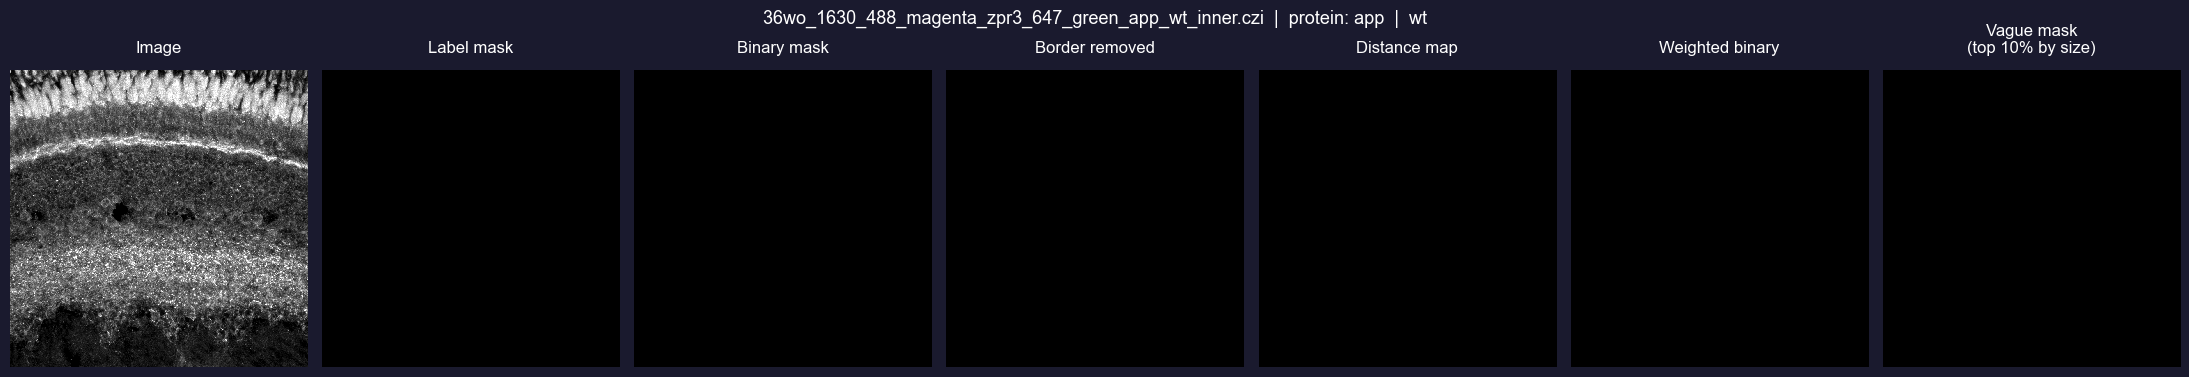

In [16]:
# 2D projection outputs
mask_2d   = _as_2d_mask(clean_mask)
label_2d  = _as_2d_labels(labeled)
raw_2d    = protein_stack.max(axis=0)

# Normalise raw for display
def norm(img):
    p1, p99 = np.percentile(img, (1, 99))
    return np.clip((img - p1) / (p99 - p1 + 1e-6), 0, 1)

# ── Derive each panel ─────────────────────────────────────────────────────────

# 1. Label mask — each object a different colour
label_rgb = label2rgb(label_2d, bg_label=0)

# 2. Binary mask
binary_2d = mask_2d.astype(np.uint8)

# 3. Border-removed binary mask — removes objects touching image edge
border_removed = clear_border(mask_2d).astype(np.uint8)

# 4. Distance map — Euclidean distance transform of binary mask
#    Bright centre = far from edge of object; useful for separating touching puncta
distance_map = distance_transform_edt(mask_2d)
distance_map = distance_map / distance_map.max() if distance_map.max() > 0 else distance_map

# 5. Weighted binary mask — binary mask edges highlighted
#    Shows object boundaries: interior dimmer, edges bright
boundaries = find_boundaries(mask_2d, mode="inner").astype(np.float32)
weighted   = (mask_2d.astype(np.float32) * 0.4) + (boundaries * 1.0)
weighted   = np.clip(weighted, 0, 1)

# 6. Vague mask — only large puncta kept (top 10% by size)
#    Highlights dominant aggregates only
if label_2d.max() > 0:
    sizes        = np.bincount(label_2d.ravel())[1:]
    size_thresh  = np.percentile(sizes, 90)
    large_labels = np.flatnonzero(sizes >= size_thresh) + 1
    vague_mask = np.isin(label_2d, large_labels).astype(np.uint8)
else:
    vague_mask = np.zeros_like(binary_2d)

# ── Plot ──────────────────────────────────────────────────────────────────────
panels = [
    (norm(raw_2d),   "gray",   "Image"),
    (label_rgb,      None,     "Label mask"),
    (binary_2d,      "gray",   "Binary mask"),
    (border_removed, "gray",   "Border removed"),
    (distance_map,   "gray",   "Distance map"),
    (weighted,       "gray",   "Weighted binary"),
    (vague_mask,     "gray",   "Vague mask\n(top 10% by size)"),
]

fig, axes = plt.subplots(1, len(panels), figsize=(22, 4))
fig.suptitle(
    f"{meta['file_name']}  |  protein: {meta['protein']}  |  {meta['condition']}"
)
for ax, (img, cmap, title) in zip(axes, panels):
    ax.imshow(img, cmap=cmap, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")

plt.show()

---

# 7: Thresholding methods comparison
Checking which method works the best for thresholding

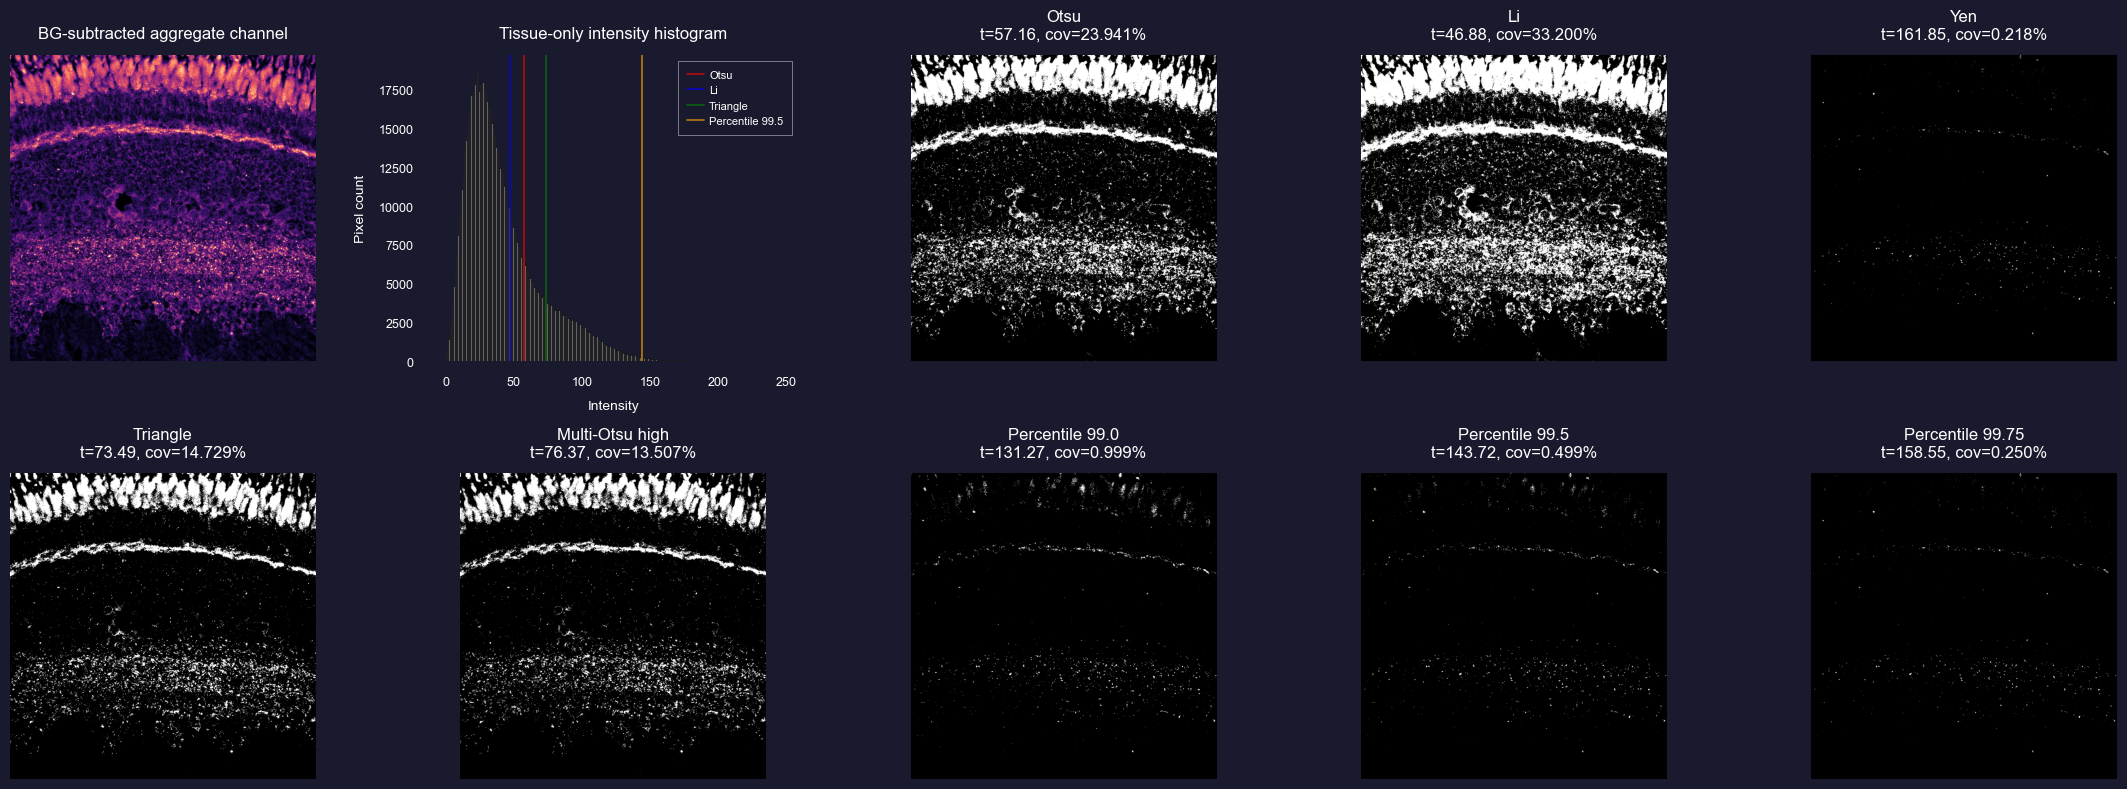

Threshold comparison
--------------------
Li                 threshold=     46.88   tissue coverage= 33.2002%
Otsu               threshold=     57.16   tissue coverage= 23.9406%
Triangle           threshold=     73.49   tissue coverage= 14.7293%
Multi-Otsu high    threshold=     76.37   tissue coverage= 13.5069%
Percentile 99.0    threshold=    131.27   tissue coverage=  0.9992%
Percentile 99.5    threshold=    143.72   tissue coverage=  0.4995%
Percentile 99.75   threshold=    158.55   tissue coverage=  0.2498%
Yen                threshold=    161.85   tissue coverage=  0.2181%


In [17]:
def preview_threshold_methods(stack_bg, tissue_mask):
    proj = stack_bg.max(axis=0).astype(np.float32)
    tissue_2d = tissue_mask.max(axis=0).astype(bool)

    vals = proj[tissue_2d]
    vals = vals[np.isfinite(vals)]
    vals = vals[vals > 0]

    thresholds = {
        "Otsu": filters.threshold_otsu(vals),
        "Li": filters.threshold_li(vals),
        "Yen": filters.threshold_yen(vals),
        "Triangle": filters.threshold_triangle(vals),
        "Multi-Otsu high": filters.threshold_multiotsu(vals, classes=3)[-1],
        "Percentile 99.0": np.percentile(vals, 99.0),
        "Percentile 99.5": np.percentile(vals, 99.5),
        "Percentile 99.75": np.percentile(vals, 99.75),
    }

    fig, axes = plt.subplots(2, 5, figsize=(22, 8))
    axes = axes.ravel()

    p1, p99 = np.percentile(vals, (1, 99.8))
    display = np.clip((proj - p1) / (p99 - p1 + 1e-6), 0, 1)

    axes[0].imshow(display, cmap="magma")
    axes[0].set_title("BG-subtracted aggregate channel")
    axes[0].axis("off")

    axes[1].hist(vals, bins=256, alpha=0.7, color="gray", edgecolor="black")
    axes[1].set_title("Tissue-only intensity histogram")
    axes[1].set_xlabel("Intensity")
    axes[1].set_ylabel("Pixel count")
    
    # Draw all threshold methods on histogram for comparison
    threshold_colors = {
        "Otsu": "red",
        "Li": "blue",
        "Triangle": "green",
        "Percentile 99.5": "orange",
    }
    
    for name, t in thresholds.items():
        if name in threshold_colors:
            axes[1].axvline(t, linewidth=1.2, label=name, color=threshold_colors[name], alpha=0.7)
    
    axes[1].legend(loc="upper right", fontsize=8)
 
    for ax, (name, t) in zip(axes[2:], thresholds.items()):
        mask = (proj > t) & tissue_2d
        coverage = 100 * mask.sum() / max(1, tissue_2d.sum())
        ax.imshow(mask, cmap="gray")
        ax.set_title(f"{name}\nt={t:.2f}, cov={coverage:.3f}%")
        ax.axis("off")
 
    for ax in axes[len(thresholds) + 2:]:
        ax.axis("off")
 
    plt.show()

    print("Threshold comparison")
    print("--------------------")
    for name, t in sorted(thresholds.items(), key=lambda x: x[1]):
        mask = (proj > t) & tissue_2d
        coverage = 100 * mask.sum() / tissue_2d.sum()
        print(f"{name:18s} threshold={t:10.2f}   tissue coverage={coverage:8.4f}%")

preview_threshold_methods(stack_bg, tissue_mask)